In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('perceptron_pass_fail.csv')
df.head(2)

,hours_studied,attendance_pct,passed
0,7.74,68.7,1
1,4.39,85.7,1


In [10]:
df.shape


(200, 3)

<Axes: xlabel='hours_studied', ylabel='attendance_pct'>

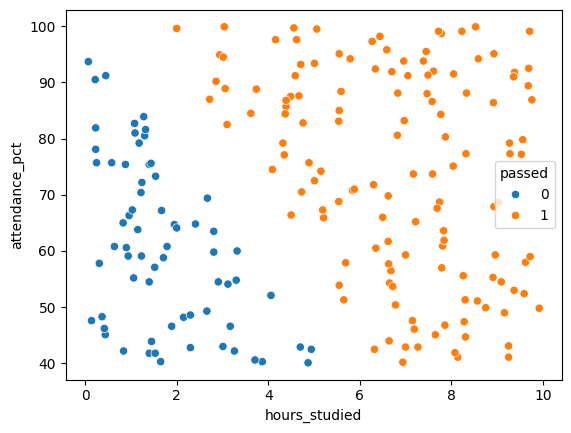

In [6]:
sns.scatterplot(df, x='hours_studied', y='attendance_pct', hue = df['passed'])

In [7]:
X = df.iloc[:, 0:2]
Y = df.iloc[:, -1]

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.1, random_state = 2) 
X_train

,hours_studied,attendance_pct
23,1.54,73.3
25,7.45,95.5
6,7.86,46.8
134,2.81,59.8
165,9.37,53.0
...,...,...
43,0.07,93.7
22,0.44,45.1
72,1.67,67.2
15,6.32,42.5


In [13]:
from sklearn.linear_model import Perceptron

p = Perceptron()

In [14]:
p.fit(X, Y)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0


In [15]:
p.coef_

array([[828.71, -38.2 ]])

In [16]:
p.intercept_

array([-147.])

In [ ]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X.values, Y.values, clf=p, legend =2)

In [20]:
df2 = pd.read_csv('perceptron_10_features.csv')
df2.head(2)

,hours_studied,attendance_pct,assignments_done,quiz_avg,sleep_hours,practice_tests,library_visits,screen_time_hrs,tutoring_sessions,prev_grade,passed
0,7.76,83.13,13.08,65.99,5.19,3.39,6.34,5.26,9.49,16.42,1
1,2.25,93.96,8.41,88.98,9.00,1.68,18.12,5.15,9.07,63.66,1


In [21]:
df2.shape

(400, 11)

<Axes: xlabel='hours_studied', ylabel='attendance_pct'>

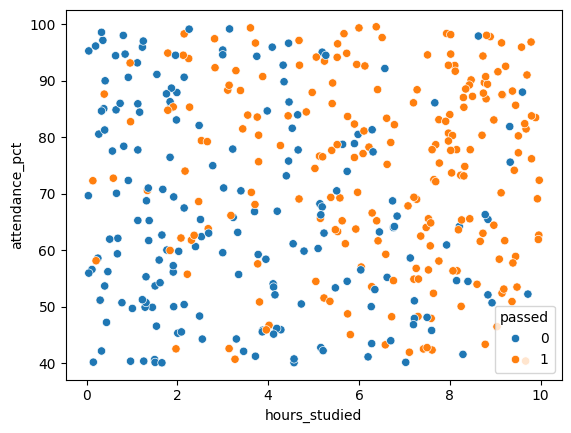

In [22]:
sns.scatterplot(df2, x='hours_studied', y='attendance_pct', hue = df2['passed'])

<Axes: xlabel='hours_studied', ylabel='assignments_done'>

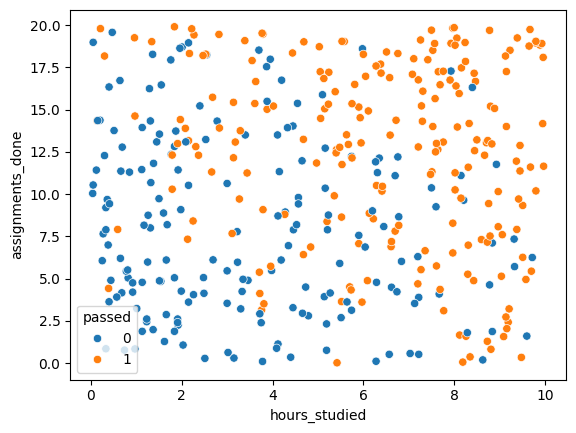

In [23]:
sns.scatterplot(df2, x='hours_studied', y='assignments_done', hue = df2['passed'])

<Axes: xlabel='hours_studied', ylabel='quiz_avg'>

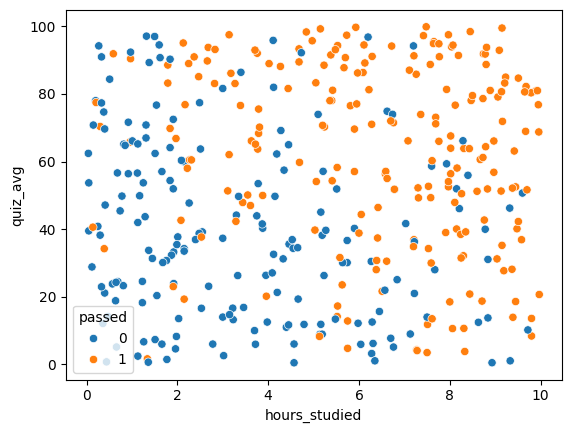

In [24]:
sns.scatterplot(df2, x='hours_studied', y='quiz_avg', hue = df2['passed'])

In [25]:
X2 = df2.iloc[:, 0:10]
Y2 = df2.iloc[:, -1]

In [27]:
from sklearn.model_selection import train_test_split

X_train2, X_test2, Y_train2, Y_test2 = train_test_split(X2, Y2, test_size = 0.1, random_state = 2) 
X_train2

,hours_studied,attendance_pct,assignments_done,quiz_avg,sleep_hours,practice_tests,library_visits,screen_time_hrs,tutoring_sessions,prev_grade
200,8.67,61.57,12.30,60.61,6.43,2.66,14.09,6.20,11.42,42.53
332,4.97,87.96,11.84,95.71,5.25,2.96,20.12,5.55,2.27,66.87
100,8.11,92.73,15.95,47.92,8.20,2.59,28.03,3.76,8.38,75.20
114,9.48,53.47,0.34,40.13,8.89,0.99,2.42,0.15,10.98,84.68
141,1.12,93.20,11.45,56.60,5.98,7.68,8.52,3.17,5.95,11.29
...,...,...,...,...,...,...,...,...,...,...
299,7.20,46.81,6.30,94.20,5.03,0.74,20.62,8.10,2.94,59.90
22,6.29,66.60,10.51,91.09,5.38,4.45,18.39,3.37,11.93,71.49
72,3.76,83.59,3.15,92.02,6.21,9.53,8.64,0.11,8.26,36.72
15,9.89,83.50,18.82,80.88,6.44,4.09,17.05,9.89,7.17,3.71


In [36]:
from sklearn.preprocessing import StandardScaler

S2 = StandardScaler()
X_train2_trf = S2.fit_transform(X_train2)
X_test2_trf = S2.transform(X_test2)

In [37]:
from sklearn.linear_model import Perceptron

p2 = Perceptron()

In [38]:
p2.fit(X2, Y2)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0


In [39]:
p2.coef_

array([[  972.48,   -23.74,   350.13,   111.94,  -630.29,   392.74,
          -31.03, -1070.81,    85.61,    66.27]])

In [40]:
p2.intercept_

array([-161.])

C:\Users\lands\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


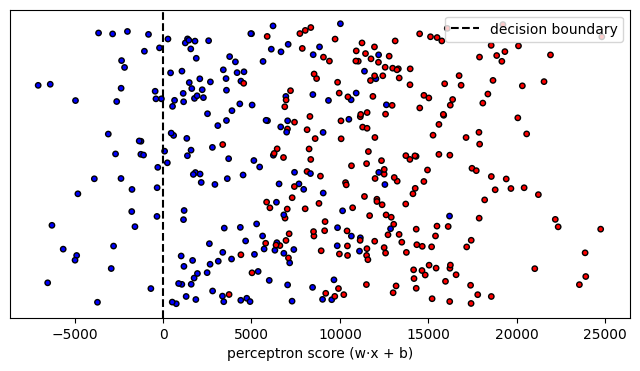

In [42]:
score = p2.decision_function(X2.values)      # same scaled/unscaled X used in training

plt.figure(figsize=(8, 4))
plt.scatter(score, np.random.uniform(-0.3, 0.3, len(score)), c=Y2, cmap='bwr', s=15, edgecolor='k')
plt.axvline(0, color='k', ls='--', label='decision boundary')
plt.xlabel('perceptron score (w·x + b)'); plt.yticks([]); plt.legend()
plt.show()